In [15]:
! pip install scikit-learn matplotlib seaborn pandas numpy -q

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay
)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [17]:
! pip install ucimlrepo

In [18]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [19]:
# Combine X and y into one working dataframe
heart_df = pd.concat([X, y], axis=1)
target_col = y.columns[0]   # this will be 'num'

print("Shape:", heart_df.shape)
print("Target column detected as:", target_col)
heart_df.head()

Shape: (303, 14)
Target column detected as: num


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [20]:
print(heart_df.dtypes)

print(heart_df.describe().T)

missing_summary = heart_df.isna().sum()
missing_summary = missing_summary[missing_summary > 0]
print("Columns with missing values:\n", missing_summary if not missing_summary.empty else "None found")

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object
          count        mean        std    min    25%    50%    75%    max
age       303.0   54.438944   9.038662   29.0   48.0   56.0   61.0   77.0
sex       303.0    0.679868   0.467299    0.0    0.0    1.0    1.0    1.0
cp        303.0    3.158416   0.960126    1.0    3.0    3.0    4.0    4.0
trestbps  303.0  131.689769  17.599748   94.0  120.0  130.0  140.0  200.0
chol      303.0  246.693069  51.776918  126.0  211.0  241.0  275.0  564.0
fbs       303.0    0.148515   0.356198    0.0    0.0    0.0    0.0    1.0
restecg   303.0    0.990099   0.994971    0.0    0.0    1.0    2.0    2.0
thalach   303.0  149.607261  22.875003   71.0  133.5  153.0  166.0  202.0
exang     303.0    0.326733   0.469794  

In [21]:
# Separate handling: median for continuous, mode for categorical/discrete
continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

for col in continuous_cols:
    if heart_df[col].isna().any():
        median_val = heart_df[col].median()
        heart_df[col] = heart_df[col].fillna(median_val)
        print(f"Filled {col} with median: {median_val}")

for col in categorical_cols:
    if heart_df[col].isna().any():
        mode_val = heart_df[col].mode(dropna=True)[0]
        heart_df[col] = heart_df[col].fillna(mode_val)
        print(f"Filled {col} with mode: {mode_val}")

assert heart_df.isna().sum().sum() == 0, "Still missing values after imputation"
print("Missing values remaining:", heart_df.isna().sum().sum())

Filled ca with mode: 0.0
Filled thal with mode: 3.0
Missing values remaining: 0


In [22]:
# Binarize the target
heart_df["disease_present"] = (heart_df[target_col] > 0).astype(int)

print(heart_df["disease_present"].value_counts(normalize=True).rename("proportion"))

disease_present
0    0.541254
1    0.458746
Name: proportion, dtype: float64


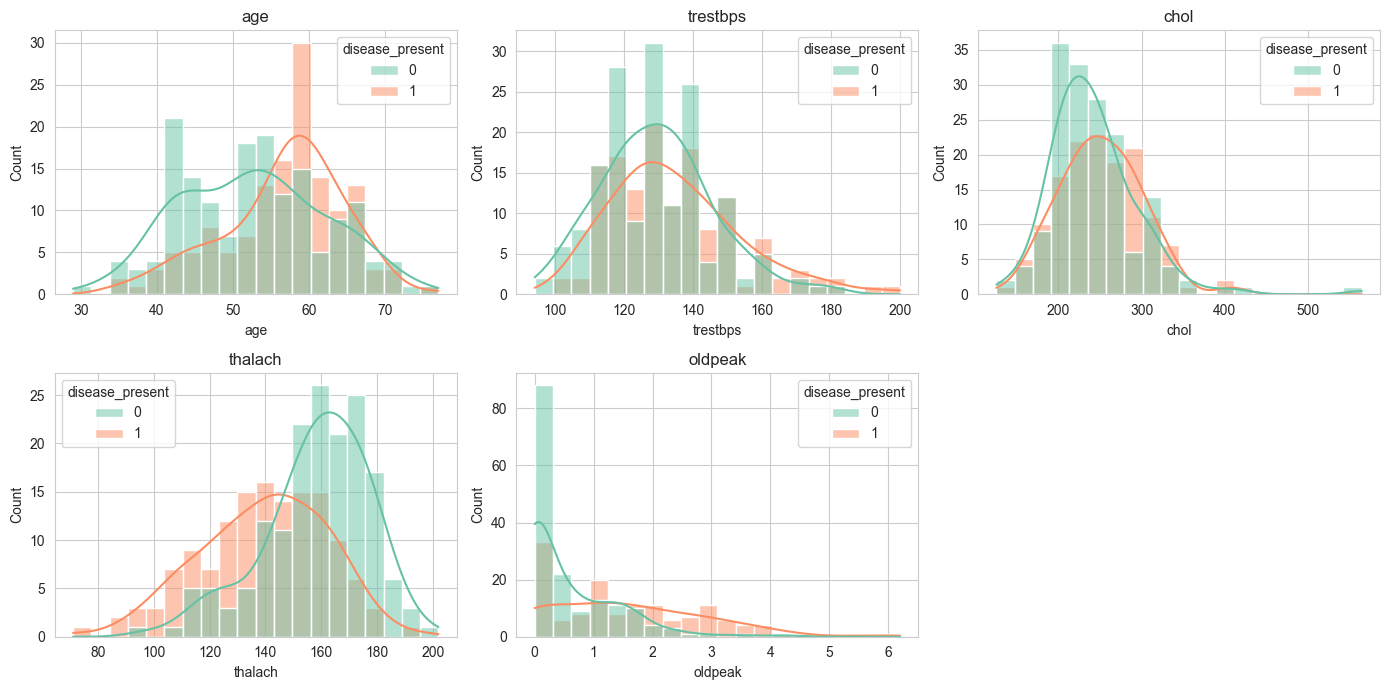

In [23]:
# EDA: feature distributions
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=heart_df, x=col, hue="disease_present", kde=True, ax=ax, bins=20, palette="Set2")
    ax.set_title(col)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

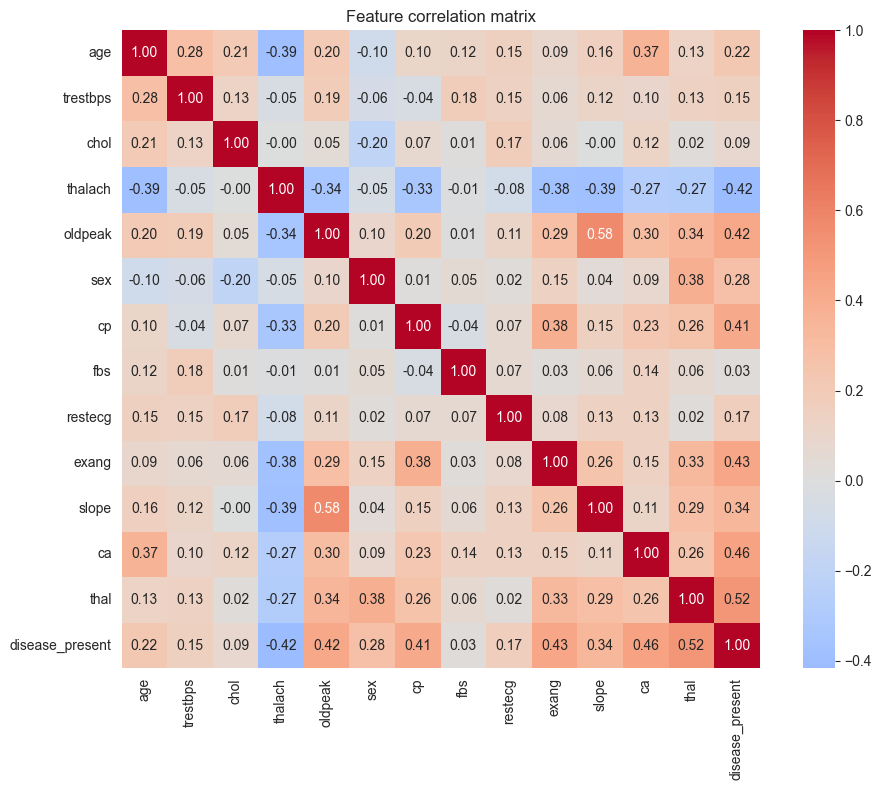

In [24]:
# EDA: correlation structure
corr_cols = numeric_cols + ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal", "disease_present"]
corr_matrix = heart_df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

In [25]:
# logistic regression
feature_cols = [c for c in heart_df.columns if c not in [target_col, "disease_present"]]

X_model = heart_df[feature_cols]
y_model = heart_df["disease_present"]

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.2, random_state=7, stratify=y_model
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

baseline_clf = LogisticRegression(max_iter=1000, random_state=7)
baseline_clf.fit(X_train_scaled, y_train)

y_pred  = baseline_clf.predict(X_test_scaled)
y_proba = baseline_clf.predict_proba(X_test_scaled)[:, 1]

/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/pankurajasaivardhan/Documents/AIH/aih/lib/python3.10/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning:

Accuracy : 0.885
ROC AUC  : 0.963


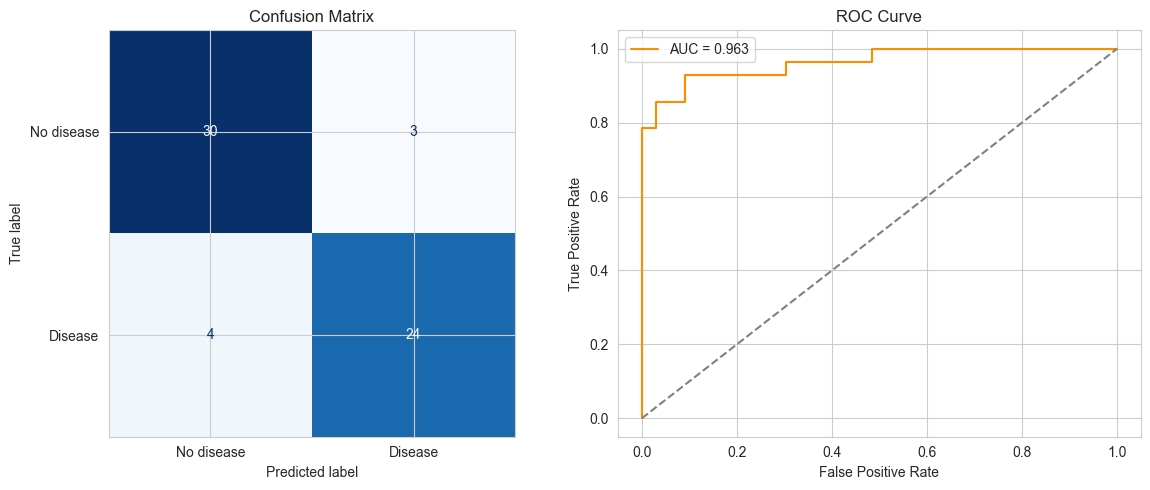

In [26]:
# Evaluation
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy : {acc:.3f}")
print(f"ROC AUC  : {auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix")

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}", color="darkorange")
ax[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve")
ax[1].legend()

plt.tight_layout()
plt.show()

#  3. Signal data ingestion (ECG)

In [27]:
! pip install wfdb

In [28]:
import wfdb

record_name = "100"


ecg_record = wfdb.rdrecord(record_name, pn_dir="mitdb")
ecg_annotation = wfdb.rdann(record_name, "atr", pn_dir="mitdb")

print("Signal shape:", ecg_record.p_signal.shape)
print("Sampling frequency:", ecg_record.fs, "Hz")
print("Channel names:", ecg_record.sig_name)
print("Number of annotated beats:", len(ecg_annotation.sample))

Signal shape: (650000, 2)
Sampling frequency: 360 Hz
Channel names: ['MLII', 'V5']
Number of annotated beats: 2274


In [29]:
import numpy as np
import pandas as pd

# MLII is channel 0 — the standard lead used for beat detection in most MIT-BIH studies
ecg_signal = ecg_record.p_signal[:, 0]
fs = ecg_record.fs

ann_samples = ecg_annotation.sample
ann_symbols = ecg_annotation.symbol

annotation_df = pd.DataFrame({"sample_index": ann_samples, "beat_type": ann_symbols})
annotation_df["time_sec"] = annotation_df["sample_index"] / fs

print("Beat type counts:\n", annotation_df["beat_type"].value_counts())
print("\nFirst few annotations:")
print(annotation_df.head())
print(f"\nRecording duration: {len(ecg_signal)/fs:.1f} seconds")

Beat type counts:
 beat_type
N    2239
A      33
+       1
V       1
Name: count, dtype: int64

First few annotations:
   sample_index beat_type  time_sec
0            18         +  0.050000
1            77         N  0.213889
2           370         N  1.027778
3           662         N  1.838889
4           946         N  2.627778

Recording duration: 1805.6 seconds


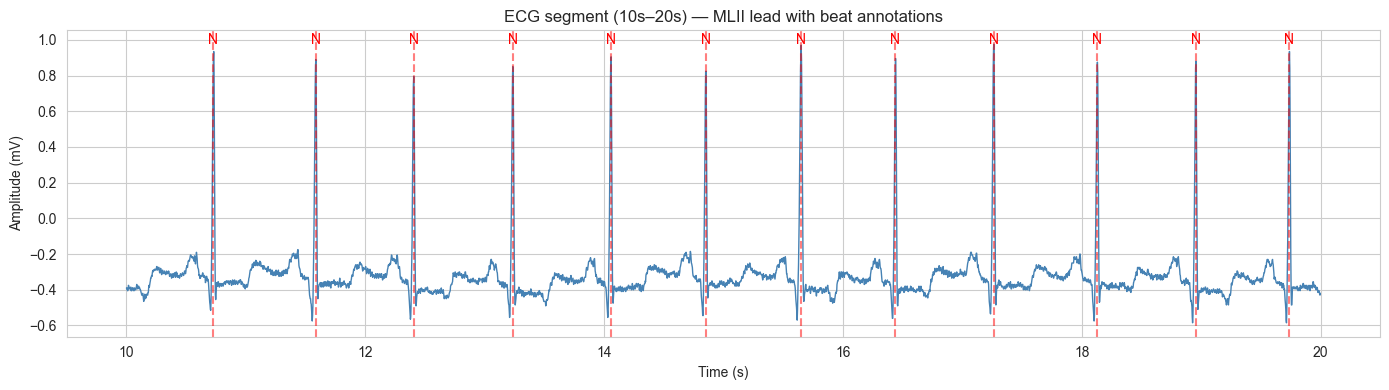

In [30]:
import matplotlib.pyplot as plt

# Look at a 10-second window so individual beats and their labels are visible
window_start_sec = 10
window_end_sec = 20

start_idx = int(window_start_sec * fs)
end_idx = int(window_end_sec * fs)

time_axis = np.arange(start_idx, end_idx) / fs
signal_segment = ecg_signal[start_idx:end_idx]

# Keep only annotations that fall inside this window
segment_anns = annotation_df[
    (annotation_df["sample_index"] >= start_idx) & (annotation_df["sample_index"] < end_idx)
]

plt.figure(figsize=(14, 4))
plt.plot(time_axis, signal_segment, color="steelblue", linewidth=1)

for _, row in segment_anns.iterrows():
    plt.axvline(row["time_sec"], color="red", linestyle="--", alpha=0.5)
    plt.text(row["time_sec"], signal_segment.max(), row["beat_type"],
              color="red", fontsize=10, ha="center")

plt.title(f"ECG segment ({window_start_sec}s–{window_end_sec}s) — MLII lead with beat annotations")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.tight_layout()
plt.show()

mean_rr_sec: 0.7943
sdnn_sec: 0.0506
min_rr_sec: 0.1639
max_rr_sec: 1.1306
mean_hr_bpm: 75.9446
hr_std_bpm: 7.9301


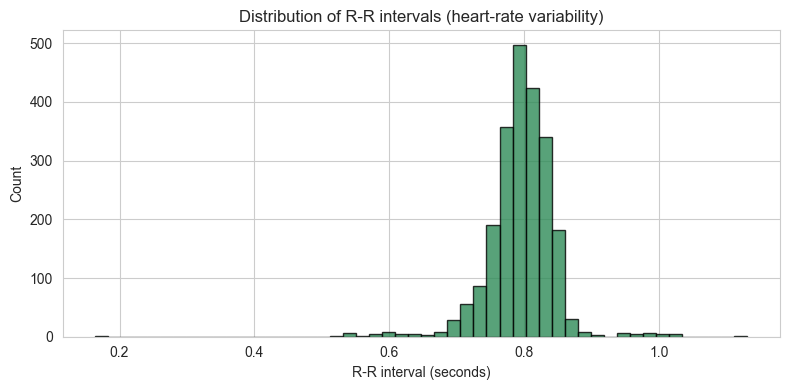

In [ ]:
# Beat interval / heart-rate variability statistics

rr_intervals = np.diff(annotation_df["sample_index"].values) / fs   # in seconds
instantaneous_hr = 60 / rr_intervals                                # beats per minute

hrv_stats = {
    "mean_rr_sec": rr_intervals.mean(),
    "sdnn_sec": rr_intervals.std(),          
    "min_rr_sec": rr_intervals.min(),
    "max_rr_sec": rr_intervals.max(),
    "mean_hr_bpm": instantaneous_hr.mean(),
    "hr_std_bpm": instantaneous_hr.std(),
}

for key, val in hrv_stats.items():
    print(f"{key}: {val:.4f}")


plt.figure(figsize=(8, 4))
plt.hist(rr_intervals, bins=50, color="seagreen", edgecolor="black", alpha=0.8)
plt.title("Distribution of R-R intervals (heart-rate variability)")
plt.xlabel("R-R interval (seconds)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 4. Textual data demonstration

In [ ]:

import re
from collections import Counter

# Small set of common stopwords — no external NLTK download needed
STOPWORDS = set("""
a an the is are was were be been being of to in on at for with and or but
if then so this that these those it its as by from not no nor has have had
""".split())

clinical_note = """
Patient is a 58-year-old male presenting with intermittent chest pain
radiating to the left arm and jaw, occurring mostly during physical
exertion and relieved by rest. He reports associated shortness of breath
and mild dizziness. No history of fever, cough, or recent trauma.
Patient denies palpitations but mentions occasional fatigue over the past
two weeks. Resting ECG shows nonspecific ST-T wave changes. Blood pressure
recorded at 145/90 mmHg. Advised further cardiac workup including stress
test, lipid profile, and troponin levels. Patient counseled on lifestyle
modification and started on low-dose aspirin pending further evaluation.
"""

def tokenize(text):
    text = text.lower()
    tokens = re.findall(r"[a-z]+", text)
    return tokens

raw_tokens = tokenize(clinical_note)
content_tokens = [t for t in raw_tokens if t not in STOPWORDS]

print("Total tokens:", len(raw_tokens))
print("Content tokens (stopwords removed):", len(content_tokens))

Total tokens: 95
Content tokens (stopwords removed): 75


Top 10 clinically relevant terms:
  patient         3
  further         2
  year            1
  old             1
  male            1
  presenting      1
  intermittent    1
  chest           1
  pain            1
  radiating       1


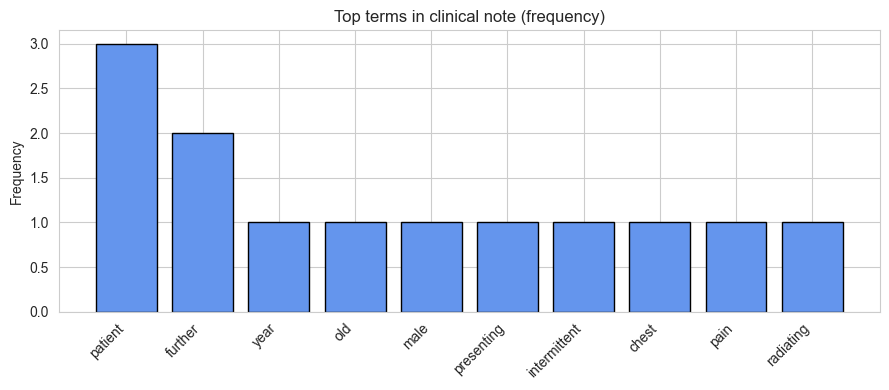

In [33]:
# Word frequency and key term extraction
term_freq = Counter(content_tokens)
top_terms = term_freq.most_common(10)

print("Top 10 clinically relevant terms:")
for term, count in top_terms:
    print(f"  {term:15s} {count}")

# Simple bar chart of top terms
terms, counts = zip(*top_terms)
plt.figure(figsize=(9, 4))
plt.bar(terms, counts, color="cornflowerblue", edgecolor="black")
plt.title("Top terms in clinical note (frequency)")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 5. Image data: synthetic chest X-ray, load, display, resize

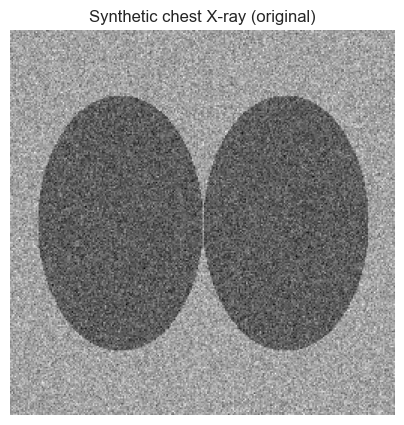

In [34]:
from PIL import Image, ImageDraw
import numpy as np

def generate_synthetic_xray(width=256, height=256, seed=1):
    """
    Creates a synthetic grayscale chest X-ray-like image.
    Used as a stand-in since no real de-identified CC0 X-ray is bundled here —
    swap this for Image.open('your_xray.png') if you have a real file.
    """
    rng = np.random.default_rng(seed)
    base = rng.normal(loc=130, scale=15, size=(height, width))

    yy, xx = np.mgrid[0:height, 0:width]
    cx, cy = width // 2, height // 2

    # Two lung-shaped darker regions (lower intensity = more radiolucent, like real lungs)
    left_lung = (((xx - (cx - 55)) ** 2) / (55 ** 2) + ((yy - cy) ** 2) / (85 ** 2)) < 1
    right_lung = (((xx - (cx + 55)) ** 2) / (55 ** 2) + ((yy - cy) ** 2) / (85 ** 2)) < 1
    base[left_lung | right_lung] -= 45

    pixels = np.clip(base, 0, 255).astype(np.uint8)
    return Image.fromarray(pixels, mode="L")

xray_img = generate_synthetic_xray()
xray_img.save("synthetic_chest_xray.png")

plt.figure(figsize=(5, 5))
plt.imshow(xray_img, cmap="gray")
plt.title("Synthetic chest X-ray (original)")
plt.axis("off")
plt.show()

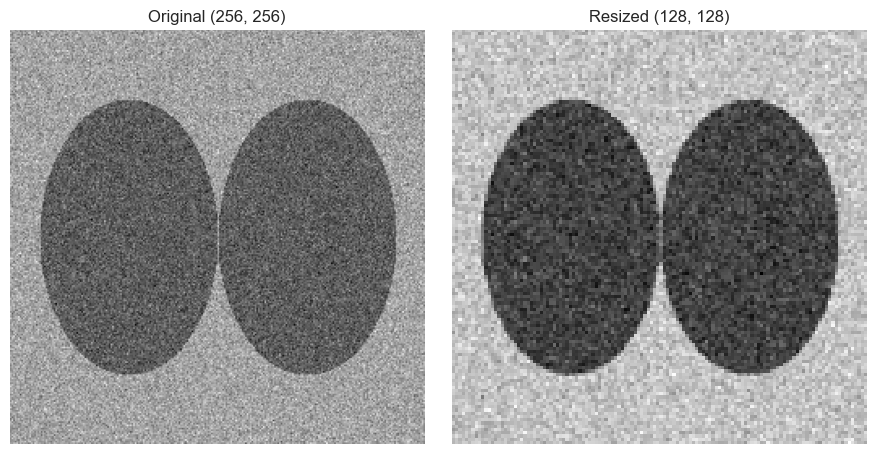

Image metadata:
  format: None
  mode: L
  size_px: (256, 256)
  min_intensity: 24
  max_intensity: 189
  mean_intensity: 109.25
  std_intensity: 26.86


In [35]:
# Resize + extract metadata
resized_xray = xray_img.resize((128, 128))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(xray_img, cmap="gray")
axes[0].set_title(f"Original {xray_img.size}")
axes[0].axis("off")

axes[1].imshow(resized_xray, cmap="gray")
axes[1].set_title(f"Resized {resized_xray.size}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

pixel_array = np.array(xray_img)
image_metadata = {
    "format": xray_img.format,
    "mode": xray_img.mode,
    "size_px": xray_img.size,
    "min_intensity": int(pixel_array.min()),
    "max_intensity": int(pixel_array.max()),
    "mean_intensity": round(float(pixel_array.mean()), 2),
    "std_intensity": round(float(pixel_array.std()), 2),
}

print("Image metadata:")
for k, v in image_metadata.items():
    print(f"  {k}: {v}")

## 6. Integration Discussion — Toward a Fused Multimodal Model
The three modalities explored in this lab — tabular clinical data, ECG signals, and
free-text notes — each capture a different, partially overlapping view of a
patient's cardiovascular risk. A fused model could combine them as follows:

**Tabular + ECG fusion**
The baseline logistic regression relies on static, single-visit measurements
(resting BP, cholesterol, `thalach` as *maximum* heart rate achieved). ECG-derived
features from a continuous recording — such as mean R-R interval, SDNN (heart-rate
variability), beat-type irregularity counts (e.g., proportion of non-`N` beats),
and ST-segment deviation over time — could be engineered as additional numeric
columns and appended to `heart_df` before training. This would let the model see
*dynamic* cardiac behavior rather than just a single measurement, which is
especially relevant since `oldpeak` and `thalach` already correlate with disease
risk in our correlation heatmap.

**Text notes as context**
Clinical notes contain symptom descriptions (e.g., "chest pain radiating to the
left arm," "shortness of breath on exertion") that are not captured by any
structured column in the tabular dataset. Simple NLP features — term frequency of
key symptom words, presence/absence flags for terms like "radiating," "angina,"
or "dizziness" — could be converted into binary or count-based features and
merged in the same way as the ECG features, giving the model early-warning signal
from patient-reported symptoms before structured test results are even available.

**Practical fusion approach**
A subject/time-aligned fusion table would need:
- A shared patient ID linking tabular records, ECG recordings, and notes.
- Feature engineering per modality (as above) reduced to fixed-length numeric
  vectors so they can sit in the same row.
- A single classifier (or a late-fusion ensemble of per-modality models) trained
  on the concatenated feature set.

**Challenges**
Real-world fusion would need to handle patients missing one or more modalities
(e.g., no ECG on file), differing time granularity (a single tabular snapshot vs.
a 30-minute continuous ECG vs. a note written at a specific visit), and privacy
requirements around de-identifying free-text notes before any NLP processing.